# Building a Transferable Adversarial Dataset with the Diverse Inputs Method (M-DI²-FGSM)

This notebook creates an **adversarial version of Imagenette** using the **Diverse Inputs Iterative Fast Gradient Sign Method with momentum (M-DI²-FGSM)**, so it can be used in a separate experiment. It is the counterpart of the MI-FGSM notebook and produces output in the same layout.

It implements:

> Xie, Zhang, Zhou, Bai, Wang, Ren, Yuille. *Improving Transferability of Adversarial Examples with Input Diversity.* CVPR 2019.
> Official code: https://github.com/cihangxie/DI-2-FGSM

## The idea

Iterative attacks such as I-FGSM greedily climb the loss of one specific model and **overfit** to it, so the adversarial examples transfer poorly. One-step attacks (FGSM) **underfit**, so they transfer a little better but are weak even on the model they were made for.

The Diverse Inputs Method fights overfitting the way data augmentation does in training. **At every attack iteration, with probability `p`, the current adversarial image is randomly transformed before the gradient is computed:**

1. **Random resizing:** the image is resized to a random size `rnd x rnd`.
2. **Random padding:** the result is zero-padded, at a random position, up to a fixed larger size.

The gradient is then taken through this transformation back to the original-size image. Because each step sees a slightly different version of the image, the perturbation cannot latch on to the quirks of one exact input, and it becomes robust to small transformations. This makes it more likely to fool other models too.

## How it relates to the other attacks

The paper (its Fig. 2) shows the whole attack family is controlled by two numbers, which you can set in the config cell:

| Setting | Result |
|---|---|
| `PROB = 0`, `MU = 0` | I-FGSM |
| `PROB = 0`, `MU > 0` | MI-FGSM (momentum only) |
| `PROB > 0`, `MU = 0` | DI²-FGSM (diverse inputs only) |
| `PROB > 0`, `MU > 0` | **M-DI²-FGSM** (both; the strongest) |

## What the paper reports

For a six-model ensemble tested on a hold-out model (their Table 3), M-DI²-FGSM transfers markedly better than MI-FGSM. For example, with Inc-v3 held out, 80.7% vs 71.4%, and with the adversarially trained Inc-v3ens3 held out, 44.6% vs 22.8%. The trade-off is that white-box success on the attacked ensemble is a little lower (about 90% vs about 97%), because the optimisation problem is harder. The probability `p` controls this trade-off: larger `p` means better transfer but weaker white-box attack.

## Workflow

| Step | What happens |
|---|---|
| 1 | Configure paths and attack hyperparameters |
| 2 | Load an *attack ensemble* (white-box) and *hold-out* models (never attacked; used only to measure transfer) |
| 3 | Read your CSV (`image path, label`) |
| 4 | Define the input-diversity transform and check it visually |
| 5 | Run M-DI²-FGSM on every image the ensemble classifies correctly |
| 6 | Save adversarial images as lossless PNGs plus a metadata CSV |
| 7 | Report white-box and black-box (transfer) fooling rates, and visualise examples |

**Compatibility:** the output folder layout and `metadata.csv` columns match the MI-FGSM notebook, so the training notebook can use this dataset by pointing `ADV_DIR` at this notebook's `OUT_DIR`.

**Tip:** do a quick test first by setting `MAX_IMAGES = 100` in the config cell, then set it back to `None` for the full run.

## 0. Setup

Uncomment and run the next cell if you need to install dependencies. `torchvision >= 0.13` is required (for the `weights="DEFAULT"` API).

In [ ]:
# %pip install torch torchvision pillow pandas matplotlib tqdm

In [12]:
import os
import csv
import json
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import torchvision.models as models
import torchvision.transforms as T
from torchvision.utils import save_image
from torch.utils.data import Dataset, DataLoader
from PIL import Image

# tqdm gives a progress bar; fall back to a no-op if it isn't installed.
try:
    from tqdm.auto import tqdm
except ImportError:
    def tqdm(x, **kwargs):
        return x

# Use the GPU if available. The attack needs many forward/backward passes,
# so a GPU makes a large difference (CPU works but is slow).
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"torch {torch.__version__} | torchvision {torchvision.__version__} | device: {device}")

torch 2.14.1+cu130 | torchvision 0.29.1+cu130 | device: cuda


## 1. Configuration

Everything you are likely to want to change lives in this one cell.

**Attack hyperparameters (defaults follow the paper's experimental setup, Sec. 4.1):**
- `EPS`: maximum per-pixel change (L-infinity bound) on the 0-255 scale. The paper uses 15; this notebook defaults to 16 to match the MI-FGSM notebook.
- `ALPHA`: step size per iteration on the 0-255 scale. The paper uses 1.
- `ITERS`: number of iterations `N`. The paper uses `N = min(eps + 4, 1.25 * eps)`, which is 20 for `eps = 16`. Note that with `ALPHA = 1` the steps can add up to more than `EPS`, so the result is clipped back into the epsilon-ball after every step (as in the paper).
- `MU`: momentum decay factor. The paper uses 1.0.
- `PROB`: probability `p` that the transformation is applied at an iteration. The paper uses 0.5 for its main experiments and 0.4 for the NIPS 2017 competition ensemble. Larger `p` gives better transferability but a lower white-box success rate.

**Input-diversity sizes:**
- `IMG_SIZE`: size of the images the attack works on (224, the standard size for the torchvision models used here).
- `DI_RESIZE_MAX`: the size images are padded up to. At each transformed iteration the image is first resized to a random `rnd` in `[IMG_SIZE, DI_RESIZE_MAX)` and then zero-padded to `DI_RESIZE_MAX x DI_RESIZE_MAX`. The paper uses 299 -> 330, i.e. about 10% larger than the input. Scaling that ratio to 224 gives about 247, so 248 is used.

**To match the earlier MI-FGSM notebook's budget** (10 iterations, step size `EPS / ITERS`), set `ITERS = 10` and `ALPHA = EPS / ITERS`. That makes the two datasets directly comparable apart from the input diversity.

**Models:**
- `ATTACK_MODELS` are the models the examples are *crafted against* (the ensemble).
- `HOLDOUT_MODELS` are **never** used during the attack. Their fooling rate is the honest measure of transferability. Pick architectures that differ from the ensemble.

In [13]:
# ----------------------------- Data -----------------------------
CSV_PATH   = "imagenette2/imagenette2/noisy_imagenette.csv"            # CSV: column 1 = image path, column 2 = label
IMG_ROOT   = "imagenette2/imagenette2/"                      # Prefix for relative paths in the CSV ("" if paths are absolute)
OUT_DIR    = "adv_imagenette_dim"    # Where the adversarial dataset will be written
MAX_IMAGES = None                    # e.g. 100 for a quick test run; None = use everything

# --------------------------- Attack settings ---------------------------
EPS        = 32                                  # L-inf budget on the 0-255 scale
ALPHA      = 1.0                                 # step size on the 0-255 scale (paper: 1)
ITERS      = int(min(EPS + 4, 1.25 * EPS))       # number of iterations N (paper's rule; 20 for EPS=16)
MU         = 1.0                                 # momentum decay factor (0 -> no momentum)
PROB       = 0.5                                 # probability p of applying the transform each iteration (0 -> none)

IMG_SIZE      = 224                              # size of the images being attacked
DI_RESIZE_MAX = 248                              # random resize in [IMG_SIZE, DI_RESIZE_MAX), then pad to this size

BATCH_SIZE = 32                      # lower this if you run out of GPU memory (VGG16 is memory hungry)
SEED       = 0                       # seed for the random transformations (makes the dataset reproducible)

# ------------------------------ Models ------------------------------
# Ensemble the attack is crafted against (logits are fused with equal weights).
ATTACK_MODELS  = ["resnet50"]
# Held-out models used ONLY to measure transferability. Must not overlap with the above.
HOLDOUT_MODELS = ["efficientnet_b0", "mobilenet_v3_large","densenet121","vgg16"]

# --------------------------- Sanity checks ---------------------------
assert not set(ATTACK_MODELS) & set(HOLDOUT_MODELS), "Hold-out models must differ from attack models"
assert os.path.exists(CSV_PATH), f"CSV not found: {CSV_PATH}"
assert 0.0 <= PROB <= 1.0, "PROB must be between 0 and 1"
assert DI_RESIZE_MAX > IMG_SIZE, "DI_RESIZE_MAX must be larger than IMG_SIZE"
print(f"Config OK. Attack = {'M-DI2-FGSM' if PROB > 0 and MU > 0 else 'DI2-FGSM' if PROB > 0 else 'MI-FGSM' if MU > 0 else 'I-FGSM'} "
      f"(eps={EPS}, alpha={ALPHA}, iters={ITERS}, mu={MU}, p={PROB})")

Config OK. Attack = M-DI2-FGSM (eps=32, alpha=1.0, iters=36, mu=1.0, p=0.5)


## 2. Loading models

### Normalisation wrapper
Torchvision models expect inputs normalised with ImageNet mean/std. If we fed them normalised images directly, our epsilon would be measured in "normalised units", which is confusing and different per channel.

Instead, we wrap each model so that it accepts **raw `[0, 1]` pixels** and normalises *inside* the forward pass. This means:
- the attack, the clipping, and `EPS/255` all live in ordinary pixel space,
- the zero-padding in the input-diversity transform is applied to raw pixels (so padding is black),
- the adversarial images we save are exactly what a user would feed in with a plain `ToTensor()`.

We also freeze the model weights (`requires_grad_(False)`). We only need gradients with respect to the **input image**, and freezing the weights saves memory.

### Different input sizes
The transform makes the attacked images slightly larger than 224 (up to `DI_RESIZE_MAX`). The torchvision models used here all end in adaptive pooling, so they accept this without any change.

In [14]:
class Normalized(nn.Module):
    """Wrap a classifier so it takes [0,1] images and applies ImageNet normalisation internally."""

    def __init__(self, model):
        super().__init__()
        self.model = model
        # register_buffer -> moves with .to(device) but is not a trainable parameter
        self.register_buffer("mean", torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1))
        self.register_buffer("std",  torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1))

    def forward(self, x):
        return self.model((x - self.mean) / self.std)


def load_model(name):
    """Load a pretrained torchvision model by name, wrapped, frozen and in eval mode."""
    ctor = getattr(models, name)            # e.g. models.resnet50
    net = ctor(weights="DEFAULT")           # best available pretrained ImageNet weights
    wrapped = Normalized(net).eval().to(device)   # eval(): disables dropout / uses BN running stats
    for p in wrapped.parameters():
        p.requires_grad_(False)             # we only need gradients w.r.t. the input
    return wrapped


print("Loading attack ensemble:", ATTACK_MODELS)
attack_models = {n: load_model(n) for n in ATTACK_MODELS}

print("Loading hold-out models:", HOLDOUT_MODELS)
holdout_models = {n: load_model(n) for n in HOLDOUT_MODELS}

# Convenient combined view for evaluation (attack models first, then hold-outs).
all_models = {**attack_models, **holdout_models}
print(f"Loaded {len(all_models)} models.")

Loading attack ensemble: ['resnet50']
Loading hold-out models: ['efficientnet_b0', 'mobilenet_v3_large', 'densenet121', 'vgg16']
Loaded 5 models.


## 3. Labels and data loading

### Label mapping
Imagenette is a 10-class subset of ImageNet, but our models predict **1000** ImageNet classes. To check whether a model is right, we map each Imagenette class to its ImageNet-1k index:

| Imagenette class | wnid | ImageNet-1k index |
|---|---|---|
| tench | n01440764 | 0 |
| English springer | n02102040 | 217 |
| cassette player | n02979186 | 482 |
| chain saw | n03000684 | 491 |
| church | n03028079 | 497 |
| French horn | n03394916 | 566 |
| garbage truck | n03417042 | 569 |
| gas pump | n03425413 | 571 |
| golf ball | n03445777 | 574 |
| parachute | n03888257 | 701 |

### CSV parsing
Column 2 of your CSV may contain **wnids**, **class names**, or **integers 0-9**. All are accepted. Integers are assumed to follow the standard Imagenette order (sorted wnids, as in the table above). **If your integers use a different ordering, the labels will be wrong, so verify this.** A header row is detected automatically.

In [15]:
# Imagenette classes in sorted-wnid order (this is the standard Imagenette label order)
WNIDS = ["n01440764", "n02102040", "n02979186", "n03000684", "n03028079",
         "n03394916", "n03417042", "n03425413", "n03445777", "n03888257"]
CLASS_NAMES = ["tench", "english_springer", "cassette_player", "chain_saw", "church",
               "french_horn", "garbage_truck", "gas_pump", "golf_ball", "parachute"]
IMAGENETTE_TO_IN1K = [0, 217, 482, 491, 497, 566, 569, 571, 574, 701]


def _norm(s):
    """Normalise a label string: lower-case, spaces/hyphens -> underscores."""
    return s.strip().lower().replace(" ", "_").replace("-", "_")


# Build a lookup that accepts wnids, class names, or integer strings -> Imagenette index 0..9
LABEL_LOOKUP = {}
for i, (wnid, cname) in enumerate(zip(WNIDS, CLASS_NAMES)):
    LABEL_LOOKUP[wnid] = i
    LABEL_LOOKUP[cname] = i
    LABEL_LOOKUP[str(i)] = i


def parse_label(s):
    """Return the Imagenette index (0-9) for a label string, or None if unrecognised."""
    return LABEL_LOOKUP.get(_norm(s))


def read_csv(path, img_root):
    """Read (image_path, imagenette_label) pairs from the CSV."""
    items = []
    with open(path, newline="") as f:
        for n, row in enumerate(csv.reader(f)):
            if len(row) < 2 or not row[0].strip():
                continue                                  # skip blank / malformed rows
            lab = parse_label(row[1])
            if lab is None:
                if n == 0:
                    continue                              # unrecognised label on row 1 -> it's a header
                raise ValueError(f"Row {n + 1}: unrecognised label {row[1]!r}. "
                                 f"Expected a wnid, class name, or integer 0-9.")
            p = row[0].strip()
            if img_root and not os.path.isabs(p):
                p = os.path.join(img_root, p)             # prepend root for relative paths
            items.append((p, lab))
    if not items:
        raise ValueError("No valid rows found in CSV.")
    return items


items = read_csv(CSV_PATH, IMG_ROOT)
if MAX_IMAGES:
    items = items[:MAX_IMAGES]

# Fail early (before any heavy compute) if image files are missing.
missing = [p for p, _ in items if not os.path.exists(p)]
if missing:
    raise FileNotFoundError(f"{len(missing)} image(s) not found, e.g. {missing[0]}. Check IMG_ROOT.")

counts = pd.Series([CLASS_NAMES[l] for _, l in items]).value_counts()
print(f"Loaded {len(items)} images. Class distribution:\n{counts}")

Loaded 13394 images. Class distribution:
cassette_player     1350
garbage_truck       1350
tench               1350
english_springer    1350
church              1350
parachute           1350
french_horn         1350
golf_ball           1350
gas_pump            1350
chain_saw           1244
Name: count, dtype: int64


### Dataset and DataLoader

Preprocessing matches the standard torchvision ImageNet evaluation pipeline: **resize to 256, center-crop to `IMG_SIZE` (224)**, convert to a tensor in `[0, 1]`. Normalisation is *not* applied here, because the model wrappers do it internally.

The dataset also returns the **index** of each image, so after filtering and batching we can still recover the original filename when saving.

Because the saved adversarial images are 224x224 crops, an experiment that loads them later should **not** resize or crop them again (that would partially destroy the perturbation). Note that the *diverse-inputs transform is used only inside the attack*. The images that are saved and evaluated are always the plain 224x224 adversarial images.

In [16]:
# Resize shorter side to 256, center crop IMG_SIZE x IMG_SIZE, convert to float tensor in [0, 1].
preprocess = T.Compose([T.Resize(256), T.CenterCrop(IMG_SIZE), T.ToTensor()])


class CSVDataset(Dataset):
    """Loads images listed in the CSV. Returns (image_tensor, imagenette_label, dataset_index)."""

    def __init__(self, items, transform):
        self.items = items
        self.transform = transform

    def __len__(self):
        return len(self.items)

    def __getitem__(self, i):
        path, label = self.items[i]
        img = Image.open(path).convert("RGB")      # force 3 channels (some files are greyscale)
        return self.transform(img), label, i


loader = DataLoader(
    CSVDataset(items, preprocess),
    batch_size=BATCH_SIZE,
    shuffle=False,        # keep order deterministic
    num_workers=2,        # set to 0 if you hit multiprocessing issues (e.g. on Windows)
)

## 4. The input-diversity transform

This is the function `T(X; p)` from the paper (its Eq. 6). Given the current adversarial image it does the following:

1. **Coin flip:** with probability `1 - p` it returns the image unchanged. With probability `p` it continues.
2. **Random resize:** it picks a random integer `rnd` in `[IMG_SIZE, DI_RESIZE_MAX)` and resizes the image to `rnd x rnd` using **nearest-neighbour** interpolation (the interpolation used in the official code).
3. **Random pad:** the remaining `DI_RESIZE_MAX - rnd` pixels are added as **zero padding**, split randomly between top/bottom and between left/right, so the image ends up at a random position inside a `DI_RESIZE_MAX x DI_RESIZE_MAX` canvas.

### Why it works inside an attack
Both operations are **differentiable**: nearest-neighbour resizing just routes each output pixel back to one source pixel, and padding adds constants. PyTorch's autograd therefore carries the gradient from the transformed image straight back to the original-size adversarial image, so the usual sign-gradient update can be applied to it.

### Notes on this implementation
- **One transform per iteration, shared by the whole batch.** The official code draws its random numbers once per forward pass, so every image in a batch gets the same transform in a given iteration (different iterations get different transforms). We follow the official code.
- **Padding colour.** Padding is zero in `[0, 1]` pixel space, i.e. black. Some implementations pad in a normalised space instead, where zero is mid-grey. The choice is not important for the method.
- **Reproducibility.** The random draws come from a dedicated `torch.Generator` seeded with `SEED`, so the dataset can be regenerated exactly (with the same batch size and image order).

In [17]:
def input_diversity(x, resize_max, prob, generator=None):
    """
    Random resizing + random zero-padding, applied with probability `prob`.
    (Xie et al. 2019, Eq. 6.)

    Args:
        x          : images, shape (B, 3, H, W), square, values in [0, 1]
        resize_max : size the image is padded up to (random resize is in [H, resize_max))
        prob       : probability of applying the transform; otherwise x is returned unchanged
        generator  : CPU torch.Generator for reproducible randomness (optional)

    Returns:
        (B, 3, resize_max, resize_max) tensor if the transform fired, else x itself (B, 3, H, W).
        The result is differentiable with respect to x.
    """
    # 1) Coin flip: with probability (1 - prob) leave the image untouched.
    if torch.rand(1, generator=generator).item() >= prob:
        return x

    img_size = x.shape[-1]

    # 2) Random resize to rnd x rnd, with rnd in [img_size, resize_max). Nearest-neighbour as in the official code.
    rnd = torch.randint(img_size, resize_max, (1,), generator=generator).item()
    resized = F.interpolate(x, size=(rnd, rnd), mode="nearest")

    # 3) Random zero-padding up to resize_max x resize_max.
    remaining = resize_max - rnd                                    # >= 1 because rnd < resize_max
    pad_top  = torch.randint(0, remaining, (1,), generator=generator).item()
    pad_left = torch.randint(0, remaining, (1,), generator=generator).item()
    pad_bottom = remaining - pad_top
    pad_right  = remaining - pad_left

    # F.pad order for the last two dims is (left, right, top, bottom)
    return F.pad(resized, (pad_left, pad_right, pad_top, pad_bottom), value=0.0)

### Visual check of the transform

The cell below applies the transform (forced to fire, `p = 1`) several times to the first image in your CSV, so you can see the random scale and position changes. It also checks that gradients really do flow back through the transform to the original image.

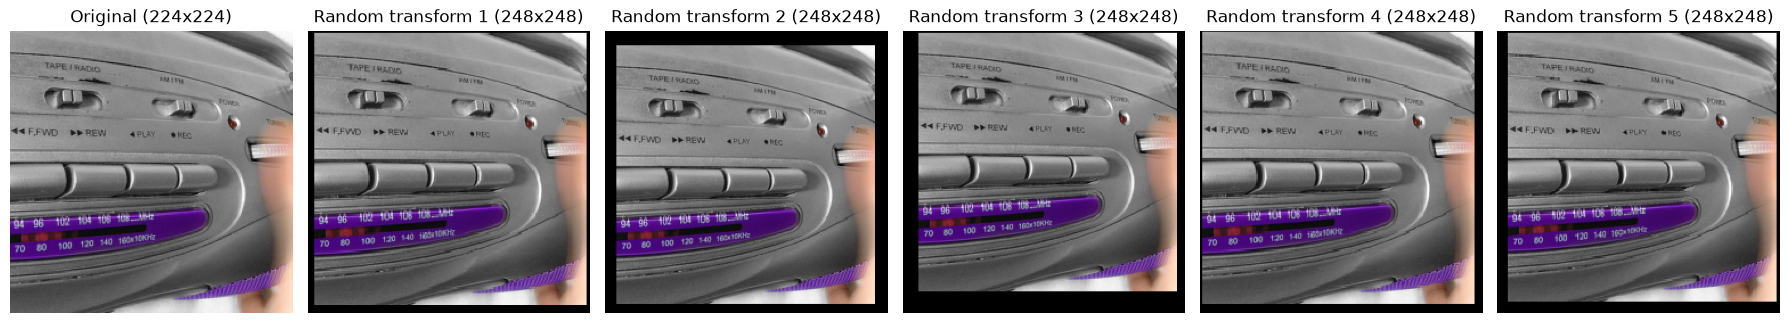

Gradient flows back through the transform: True


In [18]:
# Take the first image and show the original next to five random transforms (forced with p = 1).
x_demo = preprocess(Image.open(items[0][0]).convert("RGB")).unsqueeze(0)   # (1, 3, 224, 224), on CPU
demo_gen = torch.Generator().manual_seed(SEED)

fig, axes = plt.subplots(1, 6, figsize=(18, 3.4))
axes[0].imshow(x_demo[0].permute(1, 2, 0).numpy())
axes[0].set_title(f"Original ({IMG_SIZE}x{IMG_SIZE})")
for k in range(1, 6):
    x_t = input_diversity(x_demo, DI_RESIZE_MAX, 1.0, demo_gen)
    axes[k].imshow(x_t[0].permute(1, 2, 0).numpy())
    axes[k].set_title(f"Random transform {k} ({x_t.shape[-1]}x{x_t.shape[-1]})")
for a in axes:
    a.axis("off")
plt.tight_layout()
plt.show()

# Gradient check: the transform must be differentiable w.r.t. its input.
x_chk = x_demo.clone().requires_grad_(True)
out = input_diversity(x_chk, DI_RESIZE_MAX, 1.0, demo_gen)
out.sum().backward()
print("Gradient flows back through the transform:", x_chk.grad is not None and x_chk.grad.shape == x_chk.shape)

## 5. The M-DI²-FGSM attack

This combines the paper's Eq. 5-7 (diverse inputs) and Eq. 8 (ensemble in logits) with the momentum update from MI-FGSM.

For `N` iterations, starting from `x*_0 = x` and `g_0 = 0`:

1. **Transform:** `x_in = T(x*_n; p)`, one random draw shared by all models and all images in the batch for this iteration.
2. **Fuse logits** across the ensemble: `l(x_in) = sum_k w_k * l_k(x_in)`. With one model this is just that model's logits.
3. **Loss:** softmax cross-entropy between the fused logits and the true label. We *maximise* this.
4. **Gradient** of the loss with respect to `x*_n` (the *un-transformed* image). Autograd passes it back through the transform automatically.
5. **Normalise** the gradient by its L1 norm per image (Eq. 7). Gradient magnitudes vary between iterations, and normalising stops large-gradient iterations from dominating the momentum.
6. **Momentum:** `g_{n+1} = mu * g_n + normalised_grad`.
7. **Step:** `x*_{n+1} = x*_n + alpha * sign(g_{n+1})`.
8. **Project** into the epsilon-ball around `x` and into the valid pixel range `[0, 1]`.

Setting `PROB = 0` skips step 1's transform and gives MI-FGSM; setting `MU = 0` removes the momentum and gives DI²-FGSM.

**Note on the L1 norm:** the paper divides by the L1 norm (sum of absolute values). Using the *mean* absolute value differs only by a constant factor (the number of pixels), which does not change `sign(g)`, so the results are identical. We use the mean.

**Note on the last step:** the *saved* adversarial image is the plain 224x224 image `x*_N`. The transform is only used to compute gradients and is never applied to the final output.

In [19]:
def mdi2_fgsm(model_list, x, y, eps, alpha, iters, mu, prob, resize_max,
              weights=None, generator=None):
    """
    Non-targeted, L-infinity M-DI2-FGSM, optionally against an ensemble (fused in logits).

    Args:
        model_list : list of models mapping [0,1] images -> logits (any input size >= 224)
        x          : clean images, shape (B, 3, H, W), values in [0, 1]
        y          : true labels (ImageNet-1k indices), shape (B,)
        eps        : L-inf budget in [0,1] pixel units (i.e. EPS / 255)
        alpha      : step size in [0,1] pixel units (i.e. ALPHA / 255)
        iters      : number of iterations N
        mu         : momentum decay factor (0 disables momentum)
        prob       : probability of applying the input-diversity transform each iteration (0 disables it)
        resize_max : padded size used by the transform
        weights    : ensemble weights (default: equal); must be >= 0 and sum to 1
        generator  : CPU torch.Generator for reproducible transform randomness

    Returns:
        adversarial images, same shape as x, values in [0, 1], ||x_adv - x||_inf <= eps
    """
    if weights is None:
        weights = [1.0 / len(model_list)] * len(model_list)

    g = torch.zeros_like(x)                    # accumulated (momentum) gradient, g_0 = 0
    x_adv = x.clone().detach()                 # x*_0 = x

    for _ in range(iters):
        x_adv.requires_grad_(True)

        # Random resize + pad (with probability prob). The same transformed batch goes to every model.
        x_in = input_diversity(x_adv, resize_max, prob, generator)

        # Fuse logits across the ensemble (Eq. 8), then softmax cross-entropy.
        logits = sum(w * m(x_in) for w, m in zip(weights, model_list))
        loss = F.cross_entropy(logits, y)

        # Gradient w.r.t. the UN-transformed image; autograd chains back through the transform.
        grad = torch.autograd.grad(loss, x_adv)[0]

        # Per-image gradient normalisation (L1 up to a constant). clamp avoids divide-by-zero.
        grad = grad / grad.abs().mean(dim=(1, 2, 3), keepdim=True).clamp_min(1e-12)

        # Momentum accumulation of normalised gradients
        g = mu * g + grad

        # Step along the sign of the accumulated gradient
        x_adv = x_adv.detach() + alpha * g.sign()

        # Project: stay within eps of the original image AND inside valid pixel range [0, 1]
        x_adv = torch.min(torch.max(x_adv, x - eps), x + eps).clamp(0, 1).detach()

    return x_adv

## 6. Generating the dataset

For each batch we:

1. **Filter** to images that *every model in the attack ensemble* classifies correctly. Measuring attack success on images that were already misclassified is meaningless (the paper does the same).
2. **Attack** the remaining images with M-DI²-FGSM against the ensemble.
3. **Quantise** to 8-bit (`round(x*255)/255`). Images are stored as 8-bit PNGs, so we evaluate the *quantised* images, i.e. exactly what ends up on disk. PNG is lossless, so the perturbation is preserved (JPEG would destroy much of it).
4. **Evaluate** every model (attack and hold-out) on the plain 224x224 adversarial images.
5. **Save** each image to `OUT_DIR/<class_name>/<filename>.png`.

**Reading the stats later:**
- Fooling rate on *attack-ensemble* models = **white-box** success. Expect it to be somewhat below that of MI-FGSM, as the paper explains.
- Fooling rate on *hold-out* models = **transfer / black-box** success. This is the number that tells you how transferable the dataset is.
- For each model, the rate is computed only over images that model classified correctly when clean.

Unlike plain MI-FGSM, this attack is **random** (the transformations). It is made reproducible by seeding a dedicated generator with `SEED`; re-running with the same settings, batch size and image order gives the same dataset.

In [20]:
eps = EPS / 255.0                                           # budget in [0,1] pixel units
alpha = ALPHA / 255.0                                       # step size in [0,1] pixel units
to_in1k = torch.tensor(IMAGENETTE_TO_IN1K, device=device)   # Imagenette idx -> ImageNet-1k idx
gen = torch.Generator().manual_seed(SEED)                   # drives the random resize / pad draws

for c in CLASS_NAMES:                                       # one output folder per class
    os.makedirs(os.path.join(OUT_DIR, c), exist_ok=True)

# Running counts per model: how many correctly-classified images got fooled.
stats = {name: {"fooled": 0, "evaluated": 0} for name in all_models}
records = []                                                # one metadata row per saved image
n_seen, n_kept = 0, 0
t0 = time.time()

for x, y10, idx in tqdm(loader, desc="Attacking"):
    x, y10 = x.to(device), y10.to(device)
    y = to_in1k[y10]                                        # true labels as ImageNet-1k indices
    n_seen += len(x)

    # ---- 1. keep only images that ALL attack-ensemble models get right ----
    with torch.no_grad():
        keep = torch.ones(len(x), dtype=torch.bool, device=device)
        for m in attack_models.values():
            keep &= (m(x).argmax(1) == y)
    if keep.sum() == 0:
        continue
    x, y, y10 = x[keep], y[keep], y10[keep]
    idx = idx[keep.cpu()]                                   # indices must be filtered on CPU
    n_kept += len(x)

    # ---- 2. craft adversarial examples against the ensemble with M-DI2-FGSM ----
    x_adv = mdi2_fgsm(list(attack_models.values()), x, y, eps=eps, alpha=alpha, iters=ITERS,
                      mu=MU, prob=PROB, resize_max=DI_RESIZE_MAX, generator=gen)

    # ---- 3. quantise to 8-bit so we evaluate exactly what gets saved to disk ----
    x_adv = torch.round(x_adv * 255) / 255

    # ---- 4. evaluate every model on the plain (quantised, 224x224) adversarial images ----
    adv_preds, clean_oks = {}, {}
    with torch.no_grad():
        for name, m in all_models.items():
            clean_ok = (m(x).argmax(1) == y)                # was this model right on the clean image?
            adv_pred = m(x_adv).argmax(1)                   # what does it predict now?
            fooled = (adv_pred != y)
            stats[name]["fooled"] += (fooled & clean_ok).sum().item()
            stats[name]["evaluated"] += clean_ok.sum().item()
            adv_preds[name] = adv_pred.cpu()
            clean_oks[name] = clean_ok.cpu()

    # ---- 5. save images + collect metadata ----
    for i in range(len(x)):
        src_path = items[idx[i].item()][0]
        stem = os.path.splitext(os.path.basename(src_path))[0]
        cls = CLASS_NAMES[y10[i].item()]
        rel = os.path.join(cls, stem + ".png")
        if os.path.exists(os.path.join(OUT_DIR, rel)):      # avoid overwriting on duplicate filenames
            rel = os.path.join(cls, f"{stem}_{idx[i].item()}.png")
        save_image(x_adv[i].cpu(), os.path.join(OUT_DIR, rel))   # PNG = lossless

        rec = {
            "file": rel,
            "source_path": src_path,
            "label": y10[i].item(),
            "class": cls,
            "linf_255": round((x_adv[i] - x[i]).abs().max().item() * 255, 1),  # sanity: should be <= EPS
        }
        for name in all_models:
            rec[f"{name}_clean_ok"] = int(clean_oks[name][i].item())
            rec[f"{name}_adv_pred_in1k"] = adv_preds[name][i].item()
        records.append(rec)

elapsed = time.time() - t0
print(f"\nDone in {elapsed / 60:.1f} min. Processed {n_seen} images, attacked {n_kept}.")

Attacking: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 419/419 [35:29<00:00,  5.08s/it]


Done in 35.5 min. Processed 13394 images, attacked 12205.


## 7. Save metadata and report results

`metadata.csv` has one row per adversarial image: its filename, original source path, true label, measured L-infinity perturbation, and for every model whether it was correct on the clean image plus its prediction on the adversarial one (ImageNet-1k index). The columns match the MI-FGSM notebook, so the training notebook's pairing step works unchanged.

`summary.json` records all attack settings and the results, so the dataset is documented and reproducible.

The `linf_255` column is a sanity check: every value should be at most `EPS`.

In [21]:
# ---- Save per-image metadata ----
meta = pd.DataFrame(records)
meta_path = os.path.join(OUT_DIR, "metadata.csv")
meta.to_csv(meta_path, index=False)

# ---- Build the results table ----
rows = []
for name, s in stats.items():
    rows.append({
        "model": name,
        "role": "attack ensemble (white-box)" if name in attack_models else "HOLD-OUT (transfer)",
        "fooled": s["fooled"],
        "evaluated": s["evaluated"],
        "fooling_rate_%": round(100 * s["fooled"] / max(s["evaluated"], 1), 1),
    })
results = pd.DataFrame(rows)

print(f"Images in source CSV:             {n_seen}")
print(f"Correct on all attack models:     {n_kept} ({100 * n_kept / max(n_seen, 1):.1f}%)  <- size of adversarial dataset")
print(f"Max measured L-inf perturbation:  {meta['linf_255'].max()} / 255  (budget = {EPS})\n")
display(results) if "display" in globals() else print(results.to_string(index=False))

# Save a summary record of this run so the dataset is reproducible / documented.
summary = {
    "method": "M-DI2-FGSM (Xie et al., CVPR 2019)",
    "config": {"EPS": EPS, "ALPHA": ALPHA, "ITERS": ITERS, "MU": MU, "PROB": PROB,
               "IMG_SIZE": IMG_SIZE, "DI_RESIZE_MAX": DI_RESIZE_MAX, "SEED": SEED,
               "BATCH_SIZE": BATCH_SIZE, "ATTACK_MODELS": ATTACK_MODELS,
               "HOLDOUT_MODELS": HOLDOUT_MODELS, "preprocess": "Resize(256)+CenterCrop(224)"},
    "n_source_images": n_seen,
    "n_adversarial_images": n_kept,
    "results": rows,
}
with open(os.path.join(OUT_DIR, "summary.json"), "w") as f:
    json.dump(summary, f, indent=2)
print(f"\nSaved: {meta_path}, {os.path.join(OUT_DIR, 'summary.json')}")

Images in source CSV:             13394
Correct on all attack models:     12205 (91.1%)  <- size of adversarial dataset
Max measured L-inf perturbation:  32.0 / 255  (budget = 32)

             model                        role  fooled  evaluated  fooling_rate_%
          resnet50 attack ensemble (white-box)   12204      12205           100.0
   efficientnet_b0         HOLD-OUT (transfer)    8636      11722            73.7
mobilenet_v3_large         HOLD-OUT (transfer)    7630      11178            68.3
       densenet121         HOLD-OUT (transfer)    8578      10960            78.3
             vgg16         HOLD-OUT (transfer)    9764      11117            87.8

Saved: adv_imagenette_dim/metadata.csv, adv_imagenette_dim/summary.json


### How to interpret the table

- **Attack-ensemble rows** (white-box) should still be high, but expect them somewhat lower than with MI-FGSM, since attacking randomly transformed inputs is a harder optimisation problem. If they are too low, increase `ITERS`, lower `PROB`, or use a smaller `ALPHA` (the paper finds all three raise white-box success).
- **Hold-out rows** are your transferability numbers. Compared with the MI-FGSM dataset, they should be higher, particularly against models that differ most from the ensemble.
- **Ablations** (run on a small subset with `MAX_IMAGES`): `PROB = 0` gives MI-FGSM; `MU = 0` gives DI²-FGSM; `PROB = 1` gives maximum transferability at the cost of white-box success. The paper recommends a moderate `PROB` if you need white-box success to stay above a threshold.
- **More transferability:** add more or more diverse models to `ATTACK_MODELS`, or raise `EPS` (at the cost of visibility).
- **Caveat from the paper:** adversarially trained (robust) models remain much harder to fool in the black-box setting. The hold-out models here are normally trained, so the rates shown do not reflect robustly-trained targets.

## 8. Visual check

Each row shows the **clean** image, the **adversarial** image, and the **perturbation** (amplified so it is visible; the real perturbation is at most `EPS/255` per pixel). This is a quick sanity check that the images look essentially unchanged to a human.

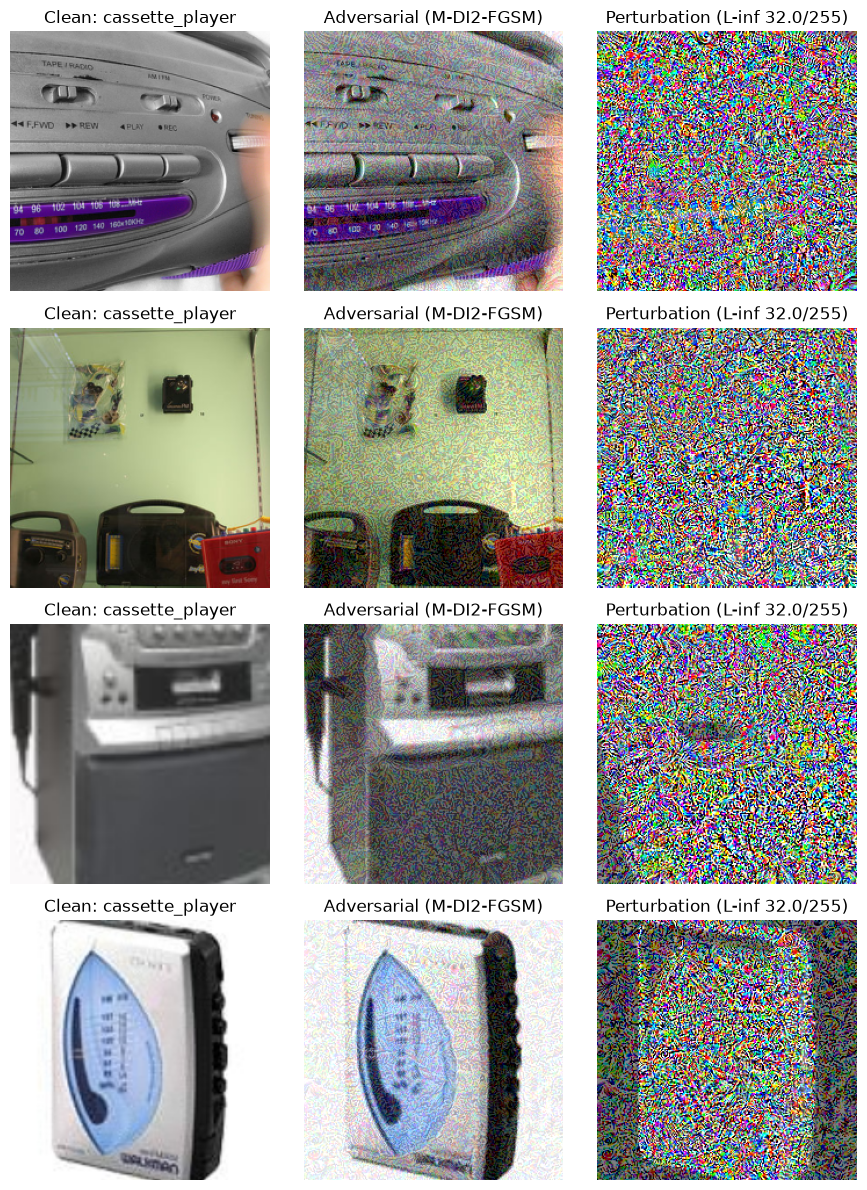

In [22]:
n_show = min(4, len(meta))
fig, axes = plt.subplots(n_show, 3, figsize=(9, 3 * n_show))
axes = np.atleast_2d(axes)

for r in range(n_show):
    row = meta.iloc[r]
    clean = preprocess(Image.open(row["source_path"]).convert("RGB"))          # same preprocessing as the attack
    adv = T.ToTensor()(Image.open(os.path.join(OUT_DIR, row["file"])).convert("RGB"))
    diff = adv - clean
    diff_vis = (diff / (2 * eps) + 0.5).clamp(0, 1)                             # map [-eps, eps] -> [0, 1]

    axes[r, 0].imshow(clean.permute(1, 2, 0).numpy());    axes[r, 0].set_title(f"Clean: {row['class']}")
    axes[r, 1].imshow(adv.permute(1, 2, 0).numpy());      axes[r, 1].set_title("Adversarial (M-DI2-FGSM)")
    axes[r, 2].imshow(diff_vis.permute(1, 2, 0).numpy()); axes[r, 2].set_title(f"Perturbation (L-inf {row['linf_255']}/255)")
    for a in axes[r]:
        a.axis("off")

plt.tight_layout()
plt.show()

## 9. Using the dataset in your other experiment

The output folder is in standard `ImageFolder` layout, so it loads directly. Copy the snippet below into your other project.

**Important details:**
- Load with a plain `ToTensor()`. **Do not resize, crop, or re-compress** the images: they are already 224x224 and any resampling or JPEG compression weakens the perturbation. (The random resize and padding used during the attack are *not* part of the saved data.)
- `ImageFolder` assigns labels alphabetically by folder name. Our folder names are chosen so this reproduces Imagenette's standard label order (`tench`=0, `english_springer`=1, ... `parachute`=9), but note this is the 0-9 Imagenette label, **not** the ImageNet-1k index. If you evaluate a 1000-class ImageNet model, map with `IMAGENETTE_TO_IN1K[label]`.
- If you feed the images to a model that expects normalisation, apply ImageNet mean/std *after* `ToTensor()` (our attack handled this inside the model wrappers).
- `metadata.csv` lets you pair each adversarial image with its original clean image via `source_path`.
- **To use it in the training notebook:** set that notebook's `ADV_DIR` to this notebook's `OUT_DIR`.

In [ ]:
# ---- Copy-paste snippet for your separate experiment ----
from torchvision.datasets import ImageFolder
import torchvision.transforms as T
from torch.utils.data import DataLoader

adv_dataset = ImageFolder(OUT_DIR, transform=T.ToTensor())      # no resize / crop / jitter!
adv_loader = DataLoader(adv_dataset, batch_size=64, shuffle=False)

print(adv_dataset.classes)          # alphabetical == Imagenette order
print(len(adv_dataset), "adversarial images")

# Example: map Imagenette labels (0-9) to ImageNet-1k indices for a 1000-class model
# imagenet_labels = torch.tensor(IMAGENETTE_TO_IN1K)[labels]